In [305]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
import statsmodels.api as sts
from statsmodels.api import OLS
from sklearn.linear_model import RidgeCV, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
from sklearn.metrics import root_mean_squared_error

import Invest_tool as it

In [306]:
data = pd.read_csv('data.csv')

Question 1: Missing values

Answer: The feature with the highest number of NaN is Engine_Horsepower

In [307]:
data.isna().sum()

Make                    0
Model                   0
Year                    0
Engine Fuel Type        3
Engine HP              69
Engine Cylinders       30
Transmission Type       0
Driven_Wheels           0
Number of Doors         6
Market Category      3742
Vehicle Size            0
Vehicle Style           0
highway MPG             0
city mpg                0
Popularity              0
MSRP                    0
dtype: int64

In [308]:
# Cleaning the name of columns

data.columns = data.columns.str.replace(' ','_')

In [309]:
for col in data.dtypes[data.dtypes == 'object'].index:

    n = len(data[col].unique())

    print(f'{col}:{data[col].unique()[0:6]}\n{n}\n')

Make:['BMW' 'Audi' 'FIAT' 'Mercedes-Benz' 'Chrysler' 'Nissan']
48

Model:['1 Series M' '1 Series' '100' '124 Spider' '190-Class' '2 Series']
915

Engine_Fuel_Type:['premium unleaded (required)' 'regular unleaded'
 'premium unleaded (recommended)' 'flex-fuel (unleaded/E85)' 'diesel'
 'electric']
11

Transmission_Type:['MANUAL' 'AUTOMATIC' 'AUTOMATED_MANUAL' 'DIRECT_DRIVE' 'UNKNOWN']
5

Driven_Wheels:['rear wheel drive' 'front wheel drive' 'all wheel drive'
 'four wheel drive']
4

Market_Category:['Factory Tuner,Luxury,High-Performance' 'Luxury,Performance'
 'Luxury,High-Performance' 'Luxury' 'Performance' 'Flex Fuel']
72

Vehicle_Size:['Compact' 'Midsize' 'Large']
3

Vehicle_Style:['Coupe' 'Convertible' 'Sedan' 'Wagon' '4dr Hatchback' '2dr Hatchback']
16



Question 2: Median for horsepower

Answer: 225 (~204)

In [310]:
np.median(data['Engine_HP'].fillna(0))

np.float64(225.0)

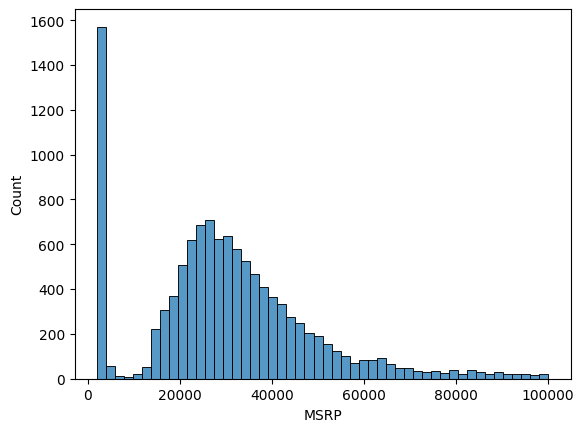

In [311]:
# Histplot of Prices

sns.histplot(data['MSRP'][data['MSRP']<100000], bins = 50, )

plt.show()

In [312]:
# Converting to log prices

log_prices = np.log1p(data['MSRP'])
data['MSRP'] = log_prices

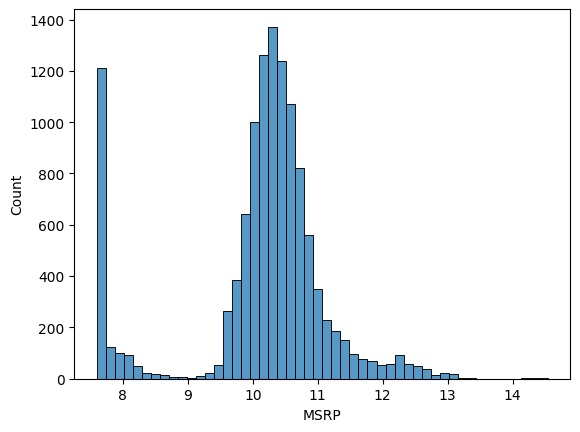

In [313]:
# Histogram

sns.histplot(log_prices, bins= 50)
plt.show()

In [314]:
# Features

base = ['Engine_HP', 'Engine_Cylinders', 'highway_MPG',
        'city_mpg', 'Popularity']

In [315]:
# Sample

x = data[base].fillna(0)
y = data['MSRP'].fillna(0)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size= 0.4, random_state= 12)
x_test, x_val, y_test, y_val = train_test_split(x_test, y_test, test_size= 0.5, random_state= 13)

In [316]:
print(len(data), len(x_train), len(x_test), len(x_val))

11914 7148 2383 2383


In [317]:
# Model 1

x_cons = sts.add_constant(x_train)

model1 = sts.OLS(y_train, x_cons).fit()

In [318]:
# Summary Model 1

model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MSRP   R-squared:                       0.544
Model:                            OLS   Adj. R-squared:                  0.544
Method:                 Least Squares   F-statistic:                     1707.
Date:                Wed, 07 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:40:59   Log-Likelihood:                -8073.9
No. Observations:                7148   AIC:                         1.616e+04
Df Residuals:                    7142   BIC:                         1.620e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                7.5155      0.074    101.098      0.000       7.370       7.661
Engine_HP            0.0093      0.000     71.780      0.000       0.009       0.010
Engine_Cylinders    -0.1198      0.009    -12.744      0.000      -0.138      -0.101
highway_MPG          0.0441      0.003     13.065      0.000       0.037       0.051
city_mpg            -0.0093      0.003     -3.247      0.001      -0.015      -0.004
Popularity       -1.228e-05   6.12e-06     -2.007      0.045   -2.43e-05   -2.88e-07
==============================================================================
Omnibus:                     1148.231   Durbin-Watson:                   1.977
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1932.084
Skew:                          -1.064   Prob(JB):                         0.00
Kurtosis:                       4.398   Cond. No.                     1.81e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.81e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [319]:
x_const = sts.add_constant(x_test)

y_pred = model1.predict(x_const)

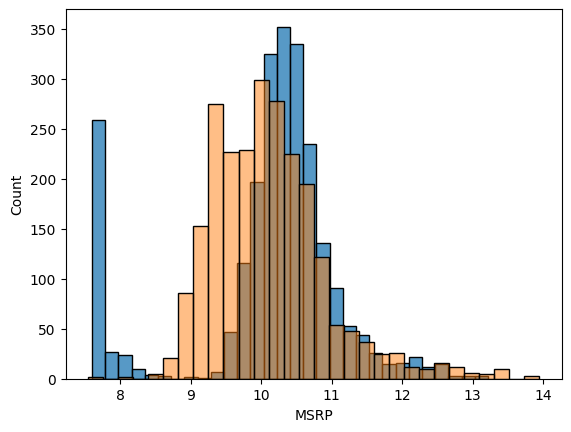

In [320]:
sns.histplot(y_test, bins= 30)
sns.histplot(y_pred, bins= 30, alpha= 0.5)
plt.show()

In [321]:
# Adding age column

data['Age'] = data['Year'] - 2017

features = base + ['Age']

In [322]:
x = data[features].fillna(0)
y = data ['MSRP'].fillna(0)

In [323]:
x_train, x_test, y_train, y_test = train_test_split(x,y, train_size=0.4, random_state= 15)
x_test, x_val, y_test, y_val = train_test_split(x_test, y_test, train_size= 0.5, random_state= 16)

In [324]:
x_const = sts.add_constant(x_train)

model2 = OLS(y_train, x_const).fit()

In [325]:
model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MSRP   R-squared:                       0.780
Model:                            OLS   Adj. R-squared:                  0.780
Method:                 Least Squares   F-statistic:                     2814.
Date:                Wed, 07 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:40:59   Log-Likelihood:                -3553.7
No. Observations:                4765   AIC:                             7121.
Df Residuals:                    4758   BIC:                             7167.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                9.4322      0.067    140.874      0.000       9.301       9.563
Engine_HP            0.0037      0.000     26.892      0.000       0.003       0.004
Engine_Cylinders     0.0764      0.008      9.125      0.000       0.060       0.093
highway_MPG         -0.0111      0.003     -3.787      0.000      -0.017      -0.005
city_mpg             0.0174      0.003      6.960      0.000       0.013       0.022
Popularity       -5.342e-05   5.29e-06    -10.094      0.000   -6.38e-05    -4.3e-05
Age                  0.0947      0.001     72.225      0.000       0.092       0.097
==============================================================================
Omnibus:                      266.437   Durbin-Watson:                   1.980
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              392.953
Skew:                           0.489   Prob(JB):                     4.69e-86
Kurtosis:                       4.012   Cond. No.                     1.89e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.89e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [326]:
x_const = sts.add_constant(x_test)

y_pred = model2.predict(x_const)

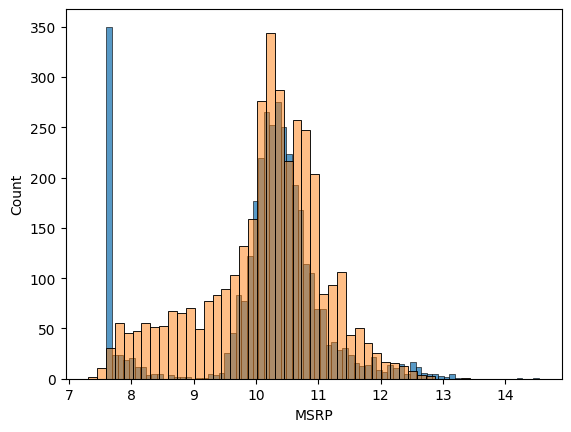

In [327]:
sns.histplot(y_test)
sns.histplot(y_pred, alpha = 0.5)
plt.show()

In [328]:
# RMSE 

def rmse(y, y_pred):
    error = y_pred - y
    error_sqrt = error**2

    mse = np.mean(error_sqrt)
    result = np.sqrt(mse)

    return result


In [329]:
categorical_variables = [
    'Make', 'Engine_Fuel_Type', 'Transmission_Type', 'Driven_Wheels',
    'Market_Category', 'Vehicle_Size', 'Vehicle_Style', 'Number_of_Doors'
]

In [330]:
for cat in categorical_variables:
    max_cat = data[cat].value_counts().nlargest(4).index
    data[cat]= data[cat].where(data[cat].isin(max_cat),'Other')

In [331]:
data['Number_of_Doors'] = data['Number_of_Doors'].astype('object')

In [332]:
dummies = pd.get_dummies(data, columns= categorical_variables, drop_first= True, dtype= int).fillna(0)

In [333]:
x = dummies.drop(columns= ['MSRP', 'Model']) 
y = dummies['MSRP']

In [334]:
x_train, x_test, y_train, y_test = train_test_split(x,y, train_size=0.4, random_state= 15)
x_test, x_val, y_test, y_val = train_test_split(x_test, y_test, train_size= 0.5, random_state= 16)

In [335]:
Results = {}

for alpha in [0.0, 0.01, 0.1, 1, 5, 10, 100]:
    RidgePipe = make_pipeline(StandardScaler(), Ridge(alpha= alpha))
    model3 = RidgePipe.fit(x_train, y_train)

    y_pred = model3.predict(x_val)

    rmse_value = root_mean_squared_error(y_val, y_pred)

    Results[str(alpha)] = rmse_value

In [336]:
df_results = pd.DataFrame(Results, index= [0]).T
df_results

,0
0.0,0.504809
0.01,0.504800
0.1,0.504757
1,0.504330
5,0.502531
10,0.500490
100,0.483165


Question 4: Best regularization

Answer: 100

In [337]:
df_results[0].idxmin()

'100'

Question 5: RMSE standard deviation

Answer: 0.007897 (~0.006)

In [338]:
df_results.std()

0    0.007897
dtype: float64

Question 6: Evaluation on test

Answer: RMSE is 0.45209 (~0.236)

In [353]:
# Final Model

RidgePipe = make_pipeline(StandardScaler(), Ridge(alpha= 100))
model4 = RidgePipe.fit(x_test, y_test)

In [354]:
y_pred = model4.predict(x_test)

In [355]:
# Metrics

root_mean_squared_error(y_test, y_pred)

0.4520889883009225

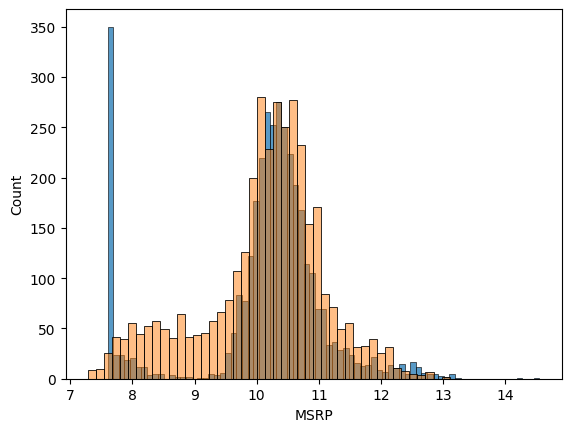

In [ ]:
sns.histplot(y_test)
sns.histplot(y_pred, alpha= 0.5)
plt.show()